# Run별·Run 내부 사출성형 EDA

질문: 불량이 일부 생산 구간에 몰리는가? 같은 공정값도 run별로 의미가 다른가? 불량 직전 값의 변화가 있는가?

- 공정 입력은 샷당 한 행, 라벨은 LH/RH 중 하나라도 불량이면 1.
- 주 분석은 대회 범위 2,393행 → 1,197샷. 원본 10/27 초기허용불량은 별도 참고.
- run 기록은 제공되지 않아 **설비별 제품 변경 또는 30분 초과 관측 간격**으로 후보 run을 추정한다. 5·10·60분 기준도 비교한다.
- unlabeled는 시간 이력에만 사용하며 정상 라벨을 가정하지 않는다.
- run 전체 요약은 사후 EDA용. 실시간 파생 피처는 직전 샷만 사용한다.
- 실행 환경: 기존 `.venv`. 커밋·푸시 없이 로컬 분석.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata, mannwhitneyu
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
TABLES = ROOT / 'reports' / 'tables'
FIGURES = ROOT / 'reports' / 'figures'
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family': ['Malgun Gothic', 'DejaVu Sans'], 'axes.unicode_minus': False, 'figure.dpi': 120})
raw = pd.read_csv(ROOT / 'data/original/moldset_labeled.csv')
raw['TimeStamp'] = pd.to_datetime(raw['TimeStamp'])
raw['product'] = raw['PART_NAME'].str.extract(r'^(CN7|RG3)', expand=False)
raw['cavity'] = raw['PART_NAME'].str.extract(r'(LH|RH)\s*$', expand=False)
raw['Reason'] = raw['Reason'].fillna('정상')
features = pd.read_csv(ROOT / 'data/moldset_labeled_cn7.csv', nrows=0).columns.drop(['Unnamed: 0', 'PassOrFail']).tolist()
raw['in_competition'] = False
mapping_checks = []
for product in ['CN7', 'RG3']:
    comp = pd.read_csv(ROOT / f'data/moldset_labeled_{product.lower()}.csv')
    candidate = raw.reset_index().set_index('Unnamed: 0')
    idx = comp['Unnamed: 0'].astype(int)
    aligned = candidate.loc[idx].reset_index(drop=True)
    assert aligned['product'].eq(product).all()
    assert np.array_equal(aligned['PassOrFail'].to_numpy(), comp['PassOrFail'].to_numpy())
    for f in features:
        x, y = aligned[f].to_numpy(float), comp[f].to_numpy(float)
        if np.ptp(x) < 1e-8:
            assert np.ptp(y) < 1e-8
            error = 0.
        else:
            coef = np.polyfit(x, y, 1)
            error = float(np.max(np.abs(np.polyval(coef, x)-y)))
            assert error < 1e-6, (product, f, error)
        mapping_checks.append({'product': product, 'feature': f, 'max_affine_error': error})
    raw.loc[aligned['index'].to_numpy(), 'in_competition'] = True
pd.DataFrame(mapping_checks).to_csv(TABLES / 'run_mapping_checks.csv', index=False)
print('Competition rows:', int(raw.in_competition.sum()), 'Original rows:', len(raw))
display(raw.groupby(['product', 'in_competition', 'Reason']).size().rename('rows').reset_index())

Competition rows: 2393 Original rows: 2607


,product,in_competition,Reason,rows
0,CN7,False,정상,204
1,CN7,False,초기허용불량,10
2,CN7,True,가스,13
3,CN7,True,미성형,4
4,CN7,True,정상,1194
5,RG3,True,가스,17
6,RG3,True,미성형,8
7,RG3,True,정상,1157


In [2]:
# 생산 이력: S14의 모든 제품을 남겨 제품 변경도 검출한다.
header = pd.read_csv(ROOT / 'data/original/unlabeled_data.csv', nrows=0).columns
usecols = ['TimeStamp', 'PART_NAME', 'EQUIP_CD'] + features
parts = []
for chunk in pd.read_csv(ROOT / 'data/original/unlabeled_data.csv', usecols=usecols, chunksize=50000):
    parts.append(chunk.loc[chunk['EQUIP_CD'].eq('S14')].copy())
history = pd.concat(parts, ignore_index=True)
history['TimeStamp'] = pd.to_datetime(history['TimeStamp'])
history['product'] = history['PART_NAME'].str.replace(r'[, ]+(LH|RH)\s*$', '', regex=True)
history.loc[history['PART_NAME'].str.startswith('CN7'), 'product'] = 'CN7'
history.loc[history['PART_NAME'].str.startswith('RG3'), 'product'] = 'RG3'
keys = ['EQUIP_CD', 'TimeStamp', 'product']
# Metadata only: never replace absent labels by normal.
labels = raw.groupby(keys, as_index=False).agg(
    PassOrFail=('PassOrFail', 'max'), in_competition=('in_competition', 'max'),
    original_rows=('PassOrFail', 'size'),
    bad_cavities=('cavity', lambda x: ''),
    Reason=('Reason', lambda x: '|'.join(sorted(set(x)-{'정상'})) or '정상'))
cavity_info = raw.loc[raw.PassOrFail.eq(1)].groupby(keys)['cavity'].agg(lambda x: '|'.join(sorted(set(x))))
labels = labels.drop(columns='bad_cavities').merge(cavity_info.rename('bad_cavities'), on=keys, how='left')
labels['bad_cavities'] = labels['bad_cavities'].fillna('')
records = pd.concat([raw[keys + features].assign(source='labeled'),
                     history[keys + features].assign(source='unlabeled')], ignore_index=True)
# Verify paired/repeated sensor values before selecting one record.
sensor_groups = records.groupby(keys)[features]
ranges = sensor_groups.max()-sensor_groups.min()
conflicts = ranges.gt(1e-4).any(axis=1)
conflict_table = ranges.loc[conflicts].reset_index()
conflict_table.to_csv(TABLES / 'run_duplicate_sensor_conflicts.csv', index=False)
print('Shots with conflicting paired/source measurements:', int(conflicts.sum()))
# Label source takes precedence if a source disagreement exists; conflicts are documented.
shots = records.drop_duplicates(keys, keep='first').merge(labels, on=keys, how='left')
shots['in_competition'] = shots['in_competition'].fillna(False).astype(bool)
shots = shots.sort_values(['EQUIP_CD', 'TimeStamp', 'product']).reset_index(drop=True)
ambiguous = shots.groupby(['EQUIP_CD', 'TimeStamp'])['product'].transform('size').gt(1)
assert not shots.loc[ambiguous, 'in_competition'].any(), 'Ambiguous competition shot'
shots.loc[ambiguous, keys].to_csv(TABLES / 'run_ambiguous_product_timestamps.csv', index=False)
print('Excluded ambiguous noncompetition timestamps:', shots.loc[ambiguous, 'TimeStamp'].nunique())
shots = shots.loc[~ambiguous].reset_index(drop=True)
shots = shots.merge(conflict_table[keys].assign(sensor_conflict=True), on=keys, how='left')
shots['sensor_conflict'] = shots['sensor_conflict'].fillna(False).astype(bool)
assert not shots.loc[shots.in_competition, 'sensor_conflict'].any(), 'Competition sensors conflict'
# Keep conflict timestamps for run boundaries, but exclude unreliable values from rolling history.
shots.loc[shots.sensor_conflict, features] = np.nan
shots['prev_gap_sec'] = shots.groupby('EQUIP_CD')['TimeStamp'].diff().dt.total_seconds()
print('Full observed history shots:', len(shots))
print('Competition shots:', shots.in_competition.sum(), 'bad shots:', shots.loc[shots.in_competition, 'PassOrFail'].sum())
display(labels.groupby(['product', 'in_competition']).agg(shots=('PassOrFail','size'), bad_shots=('PassOrFail','sum')))

Shots with conflicting paired/source measurements: 112
Excluded ambiguous noncompetition timestamps: 17
Full observed history shots: 68960
Competition shots: 1197 bad shots: 39.0


shots  bad_shots
product in_competition                  
CN7     False             107          5
        True              606         14
RG3     True              591         25

In [3]:
def assign_runs(frame, gap_minutes):
    out = frame.copy()
    switch = out['product'].ne(out.groupby('EQUIP_CD')['product'].shift())
    start = switch | out['prev_gap_sec'].gt(gap_minutes*60) | out['prev_gap_sec'].isna()
    out['run_number'] = start.cumsum()
    out['run_id'] = out.groupby('run_number')['TimeStamp'].transform('min').dt.strftime('%Y%m%d_%H%M%S') + '_' + out['product']
    out['observed_shot_seq'] = out.groupby('run_id').cumcount()+1
    out['run_elapsed_min'] = (out.TimeStamp-out.groupby('run_id').TimeStamp.transform('min')).dt.total_seconds()/60
    return out

sensitivity, run_tables = [], {}
for threshold in [5, 10, 30, 60]:
    framed = assign_runs(shots, threshold)
    contest = framed.loc[framed.in_competition]
    summary = contest.groupby(['product', 'run_id']).agg(
        labeled_shots=('PassOrFail','size'), bad_shots=('PassOrFail','sum'),
        labeled_start=('TimeStamp','min'), labeled_end=('TimeStamp','max'))
    summary['bad_rate'] = summary.bad_shots/summary.labeled_shots
    run_tables[threshold] = summary.reset_index()
    for p, g in summary.groupby(level=0):
        sensitivity.append({'gap_minutes': threshold, 'product': p, 'runs_with_labels': len(g),
                            'runs_with_defects': int(g.bad_shots.gt(0).sum()),
                            'largest_run_bad_share': g.bad_shots.max()/g.bad_shots.sum(),
                            'total_bad_shots': int(g.bad_shots.sum())})
sensitivity = pd.DataFrame(sensitivity)
sensitivity.to_csv(TABLES / 'run_threshold_sensitivity.csv', index=False)
shots = assign_runs(shots, 30)
contest = shots.loc[shots.in_competition].copy()
run_summary = run_tables[30]
full_runs = shots.groupby('run_id').agg(
    run_start=('TimeStamp','min'), run_end=('TimeStamp','max'), observed_shots=('TimeStamp','size'),
    max_internal_gap_sec=('prev_gap_sec', lambda x: x.iloc[1:].max()),
    source_labeled_only_shots=('source', lambda x: x.eq('labeled').sum()))
run_summary = run_summary.merge(full_runs, on='run_id', how='left')
run_summary.to_csv(TABLES / 'run_summary.csv', index=False, encoding='utf-8-sig')
display(run_summary)
display(sensitivity)
# Actual label coverage is uneven: denominators are labeled shots only, not all production.
contest[['run_id','TimeStamp','product','PassOrFail','Reason','bad_cavities','observed_shot_seq','run_elapsed_min','prev_gap_sec']].to_csv(
    TABLES / 'run_labeled_shots.csv', index=False, encoding='utf-8-sig')

,product,run_id,labeled_shots,bad_shots,labeled_start,labeled_end,bad_rate,run_start,run_end,observed_shots,max_internal_gap_sec,source_labeled_only_shots
0,CN7,20201016_035120_CN7,606,14.0,2020-10-16 04:57:47,2020-10-20 06:20:14,0.023102,2020-10-16 03:51:20,2020-10-20 06:20:14,8179,121.0,606
1,RG3,20201020_092218_RG3,341,15.0,2020-10-21 00:16:26,2020-10-22 08:09:24,0.043988,2020-10-20 09:22:18,2020-10-22 23:24:42,3575,126.0,341
2,RG3,20201023_010128_RG3,74,4.0,2020-10-23 01:01:28,2020-10-23 02:36:11,0.054054,2020-10-23 01:01:28,2020-10-23 02:36:11,74,1112.0,74
3,RG3,20201023_031215_RG3,176,6.0,2020-10-23 04:41:48,2020-10-23 07:46:03,0.034091,2020-10-23 03:12:15,2020-10-23 07:46:03,263,125.0,176


,gap_minutes,product,runs_with_labels,runs_with_defects,largest_run_bad_share,total_bad_shots
0,5,CN7,1,1,1.0,14
1,5,RG3,4,4,0.6,25
2,10,CN7,1,1,1.0,14
3,10,RG3,4,4,0.6,25
4,30,CN7,1,1,1.0,14
5,30,RG3,3,3,0.6,25
6,60,CN7,1,1,1.0,14
7,60,RG3,2,2,0.6,25


## 불량의 시간적 집중

연속 불량과 10개 관측 샷 단위 구간을 확인한다. unlabeled 샷은 정상으로 간주하지 않고, 연속 비교는 직전 관측 샷에도 라벨이 있을 때만 한다. 라벨이 붙은 구간에서의 비율이며 전체 생산 불량률을 의미하지 않는다.

comparable_shots  bad_shots  bad_rate
product prev_bad                                       
CN7     False                  590        4.0  0.006780
        True                    14       10.0  0.714286
RG3     False                  560       25.0  0.044643
        True                    25        0.0  0.000000

,product,run_id,longest_bad_streak
0,CN7,20201016_035120_CN7,11
1,RG3,20201020_092218_RG3,1
2,RG3,20201023_010128_RG3,1
3,RG3,20201023_031215_RG3,1


n   bad      rate
product run_position_bin                     
CN7     60-120min          54   7.0  0.129630
        120min+           552   7.0  0.012681
RG3     0-10min            10   1.0  0.100000
        10-30min           18   1.0  0.055556
        30-60min           13   1.0  0.076923
        60-120min          62   1.0  0.016129
        120min+           488  21.0  0.043033

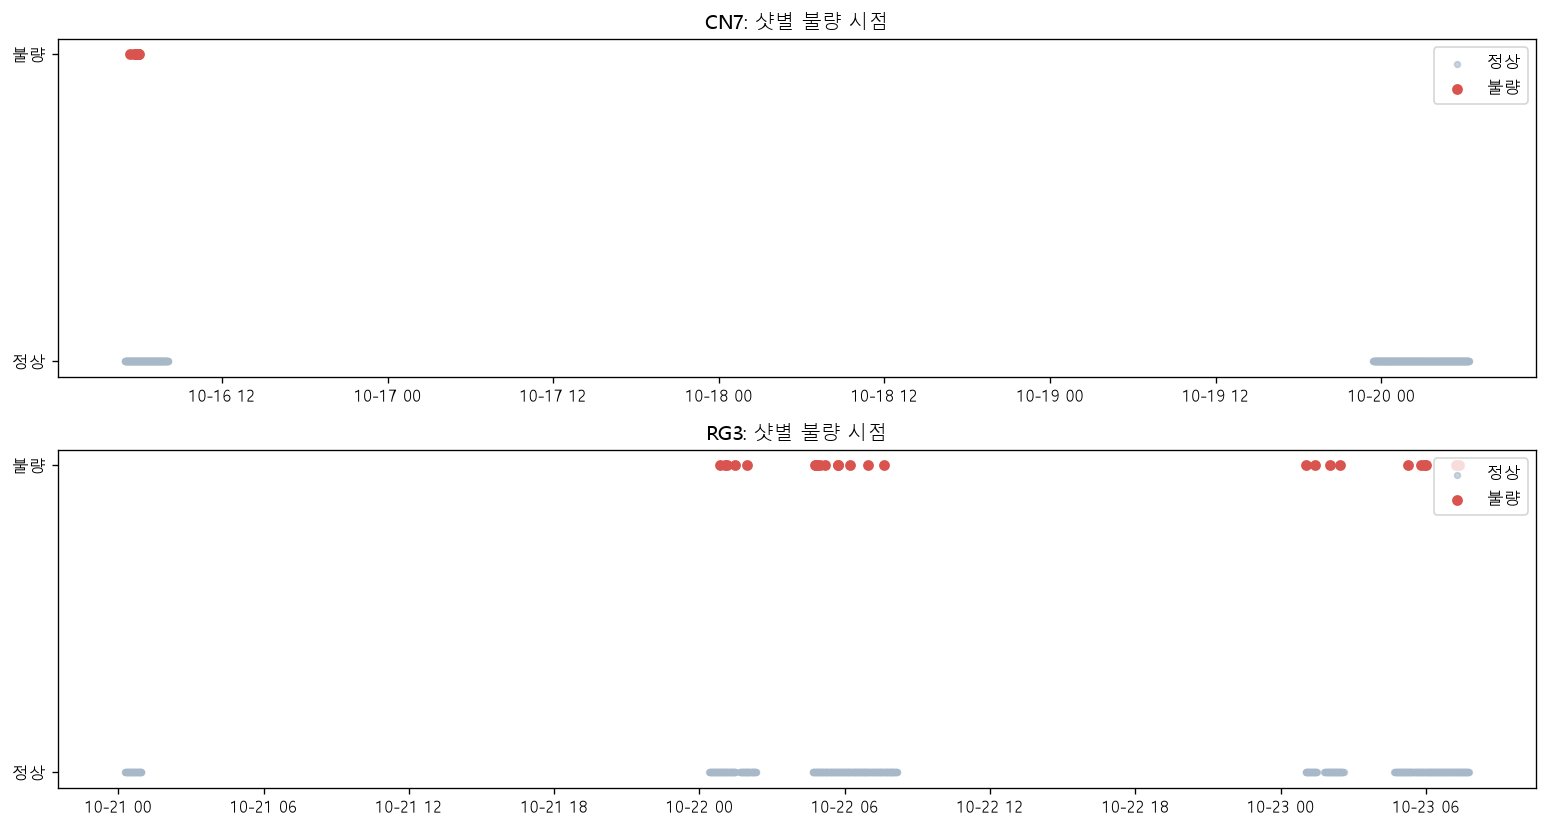

In [4]:
shots['prev_label'] = shots.groupby('run_id')['PassOrFail'].shift()
shots['prev_in_competition'] = shots.groupby('run_id')['in_competition'].shift().fillna(False).astype(bool)
contest = shots.loc[shots.in_competition].copy()
adjacent = contest.loc[contest.prev_in_competition & contest.prev_label.notna()].copy()
adjacent['prev_bad'] = adjacent.prev_label.eq(1)
conditional = adjacent.groupby(['product','prev_bad']).agg(
    comparable_shots=('PassOrFail','size'), bad_shots=('PassOrFail','sum'))
conditional['bad_rate'] = conditional.bad_shots/conditional.comparable_shots
conditional.reset_index().to_csv(TABLES / 'run_previous_defect_rates.csv', index=False)
streak_rows = []
for (p, r), g in shots.groupby(['product','run_id'], sort=False):
    if not g.in_competition.any():
        continue
    bad = (g.in_competition & g.PassOrFail.eq(1)).to_numpy()
    longest = current = 0
    for b in bad:
        current = current+1 if b else 0
        longest = max(longest,current)
    streak_rows.append({'product': p, 'run_id': r, 'longest_bad_streak': longest})
streaks = pd.DataFrame(streak_rows)
streaks.to_csv(TABLES / 'run_defect_streaks.csv', index=False)
contest['run_position_bin'] = pd.cut(contest.run_elapsed_min, [-.01,10,30,60,120,np.inf],
                                    labels=['0-10min','10-30min','30-60min','60-120min','120min+'])
position = contest.groupby(['product','run_position_bin'], observed=True).agg(
    n=('PassOrFail','size'), bad=('PassOrFail','sum'))
position['rate'] = position.bad/position.n
position.reset_index().to_csv(TABLES / 'run_position_defects.csv', index=False)
display(conditional)
display(streaks)
display(position)
fig, axes = plt.subplots(2,1,figsize=(13,7))
for ax, product in zip(axes,['CN7','RG3']):
    g = contest.loc[contest['product'].eq(product)]
    ax.scatter(g.TimeStamp, np.zeros(len(g)), color='#a7b8c9', s=12, label='정상', alpha=.6)
    b = g.loc[g.PassOrFail.eq(1)]
    ax.scatter(b.TimeStamp, np.ones(len(b)), color='#d9534f', s=30, label='불량')
    ax.set_title(f'{product}: 샷별 불량 시점')
    ax.set_yticks([0,1], ['정상','불량'])
    ax.legend(loc='upper right')
fig.tight_layout()
fig.savefig(FIGURES/'run_defect_timeline.png',bbox_inches='tight')
plt.show()

## 전체 차이와 run 내부 차이 비교

전체 정상과 비교했을 때 보이는 차이가 같은 run의 정상과 비교해도 남는지 확인한다. 평균 차이는 원래 단위, 효과 크기는 제품 전체 표준편차로 나눈 값이다. 이 분석은 사후 설명용이며 통계 검정·예측 성능 검증을 대신하지 않는다.

특히 CN7 불량 run과 정상 run의 조건 차이가 전체 상관관계에 섞이는지 본다.

In [5]:
varying = [f for f in features if contest[f].nunique()>1]
assoc_rows, within_rows, normal_run_rows = [], [], []
for product, g in contest.groupby('product'):
    for f in varying:
        scale = g[f].std()
        if scale < 1e-10:
            continue
        bad, normal = g.loc[g.PassOrFail.eq(1), f], g.loc[g.PassOrFail.eq(0), f]
        global_delta = bad.mean()-normal.mean()
        parts, ws = [], []
        for rid, rg in g.groupby('run_id'):
            b, n = rg.loc[rg.PassOrFail.eq(1), f], rg.loc[rg.PassOrFail.eq(0), f]
            if len(b) and len(n):
                diff = b.mean()-n.mean()
                parts.append(diff); ws.append(len(b))
                within_rows.append({'product': product, 'run_id': rid, 'feature': f,
                                    'bad_shots': len(b), 'normal_shots':len(n),
                                    'normal_mean': n.mean(), 'bad_mean':b.mean(),
                                    'delta_raw':diff,'delta_product_sd':diff/scale})
        local_delta = np.average(parts, weights=ws) if parts else np.nan
        assoc_rows.append({'product':product,'feature':f,'global_delta_raw':global_delta,
                           'within_run_delta_raw':local_delta,'global_delta_product_sd':global_delta/scale,
                           'within_run_delta_product_sd':local_delta/scale,
                           'sign_flip': bool(global_delta*local_delta<0),
                           'bad_shots':len(bad), 'runs_with_defects':len(parts)})
    for rid, rg in g.groupby('run_id'):
        normal = rg.loc[rg.PassOrFail.eq(0)]
        for f in varying:
            normal_run_rows.append({'product':product,'run_id':rid,'feature':f,
                                    'normal_mean':normal[f].mean(),'normal_std':normal[f].std(),
                                    'normal_shots':len(normal)})
assoc = pd.DataFrame(assoc_rows)
within = pd.DataFrame(within_rows)
assoc.to_csv(TABLES/'run_global_vs_within_associations.csv',index=False)
within.to_csv(TABLES/'run_within_feature_differences.csv',index=False)
pd.DataFrame(normal_run_rows).to_csv(TABLES/'run_normal_feature_baselines.csv',index=False)
for product in ['CN7','RG3']:
    print(product)
    display(assoc.loc[assoc['product'].eq(product)].sort_values('global_delta_product_sd',key=abs,ascending=False).head(12))

CN7


,product,feature,global_delta_raw,within_run_delta_raw,global_delta_product_sd,within_run_delta_product_sd,sign_flip,bad_shots,runs_with_defects
6,CN7,Plasticizing_Position,0.252859,0.252859,1.525094,1.525094,False,14,1
22,CN7,Mold_Temperature_4,2.807143,2.807143,1.395457,1.395457,False,14,1
7,CN7,Max_Injection_Speed,0.688779,0.688779,1.339715,1.339715,False,14,1
12,CN7,Max_Back_Pressure,-0.759605,-0.759605,-1.335334,-1.335334,False,14,1
4,CN7,Clamp_Close_Time,0.006783,0.006783,1.274928,1.274928,False,14,1
21,CN7,Mold_Temperature_3,1.740685,1.740685,1.244129,1.244129,False,14,1
13,CN7,Average_Back_Pressure,-0.311414,-0.311414,-1.186265,-1.186265,False,14,1
5,CN7,Cushion_Position,-0.005255,-0.005255,-1.004044,-1.004044,False,14,1
10,CN7,Max_Injection_Pressure,-0.069451,-0.069451,-0.725427,-0.725427,False,14,1
11,CN7,Max_Switch_Over_Pressure,0.222950,0.222950,0.705426,0.705426,False,14,1


RG3


,product,feature,global_delta_raw,within_run_delta_raw,global_delta_product_sd,within_run_delta_product_sd,sign_flip,bad_shots,runs_with_defects
41,RG3,Barrel_Temperature_5,0.148465,0.150947,0.465006,0.472777,False,25,3
27,RG3,Clamp_Close_Time,0.001332,0.000812,0.188993,0.115210,False,25,3
25,RG3,Plasticizing_Time,0.008045,0.005938,0.180442,0.133180,False,25,3
31,RG3,Max_Screw_RPM,0.010883,0.011235,0.146024,0.150744,False,25,3
39,RG3,Barrel_Temperature_3,-0.046651,-0.044573,-0.143241,-0.136862,False,25,3
43,RG3,Hopper_Temperature,-0.137619,-0.115151,-0.139811,-0.116986,False,25,3
32,RG3,Average_Screw_RPM,0.008969,0.006640,0.137884,0.102089,False,25,3
37,RG3,Barrel_Temperature_1,-0.052777,-0.052025,-0.122916,-0.121163,False,25,3
34,RG3,Max_Switch_Over_Pressure,0.050163,0.059404,0.105305,0.124705,False,25,3
29,RG3,Plasticizing_Position,-0.001326,-0.000810,-0.103564,-0.063234,False,25,3


## 불량 직전 변화와 최근 변동폭

run 안에서 직전 값과 최근 10개 **이전 관측 샷**만 사용한다. 현재·미래 라벨과 미래 값은 사용하지 않는다. 최소 5개 이전 관측이 있는 샷만 비교한다.

AUC는 탐색용 동일 데이터에서 계산한 순위 분리도이며 검증 성능이 아니다. 방향을 데이터에서 선택한 결과도 함께 표시한다. 제품별 정상/불량 비교 외에 run 내부 정상과 비교해 일관성을 확인한다.

In [6]:
past_feature_cols = []
for f in varying:
    grouped = shots.groupby('run_id')[f]
    shots[f+'__delta1'] = grouped.diff()
    shots[f+'__past10_median'] = grouped.transform(lambda x: x.shift(1).rolling(10,min_periods=5).median())
    shots[f+'__dev10'] = shots[f]-shots[f+'__past10_median']
    shots[f+'__past10_std'] = grouped.transform(lambda x: x.shift(1).rolling(10,min_periods=5).std())
    past_feature_cols.extend([f+'__delta1',f+'__dev10',f+'__past10_std'])
shots['mold_delta'] = shots['Mold_Temperature_4']-shots['Mold_Temperature_3']
shots['pressure_delta'] = shots['Max_Injection_Pressure']-shots['Max_Switch_Over_Pressure']
shots['injection_minus_filling'] = shots['Injection_Time']-shots['Filling_Time']
shots['rpm_delta'] = shots['Max_Screw_RPM']-shots['Average_Screw_RPM']
shots['back_pressure_delta'] = shots['Max_Back_Pressure']-shots['Average_Back_Pressure']
candidate_cols = varying+past_feature_cols+['mold_delta','pressure_delta','injection_minus_filling','rpm_delta','back_pressure_delta']
contest = shots.loc[shots.in_competition].copy()
def auc_rank(y,x):
    n1, n0 = int(y.sum()),int((1-y).sum())
    return float((rankdata(x)[y==1].sum()-n1*(n1+1)/2)/(n1*n0))

candidate_rows = []
for product, g in contest.groupby('product'):
    for f in candidate_cols:
        v = g[['PassOrFail',f,'run_id']].replace([np.inf,-np.inf],np.nan).dropna()
        y,x = v.PassOrFail.to_numpy(int),v[f].to_numpy(float)
        if not y.sum() or y.sum()==len(y) or np.ptp(x)<1e-10:
            continue
        auc = auc_rank(y,x)
        run_aucs, run_weights = [], []
        for rid, rg in v.groupby('run_id'):
            yy,xx = rg.PassOrFail.to_numpy(int),rg[f].to_numpy(float)
            if yy.sum()>0 and yy.sum()<len(yy):
                run_aucs.append(auc_rank(yy,xx)); run_weights.append(yy.sum())
        wa = np.average(run_aucs,weights=run_weights) if run_aucs else np.nan
        candidate_rows.append({'product':product,'feature':f,'auc_high':auc,'exploratory_direction_auc':max(auc,1-auc),
                               'within_run_auc_high':wa,
                               'within_run_auc_same_direction':wa if auc>=.5 else 1-wa,
                               'normal_median':np.median(x[y==0]),'bad_median':np.median(x[y==1]),
                               'normal_shots':int((y==0).sum()),'bad_shots':int(y.sum()),
                               'comparison_runs':len(run_aucs)})
candidates = pd.DataFrame(candidate_rows)
candidates.to_csv(TABLES/'run_past_feature_candidates.csv',index=False)
for p in ['CN7','RG3']:
    print(p, 'Top exploratory features (not held-out performance)')
    display(candidates.loc[candidates['product'].eq(p)].sort_values('within_run_auc_same_direction',ascending=False).head(15))
# A table ready for future run-grouped validation. Metadata/labels are not model inputs.
contest[keys+['run_id','PassOrFail','Reason','bad_cavities','prev_gap_sec','observed_shot_seq','run_elapsed_min']+candidate_cols].to_csv(
    TABLES/'run_shot_feature_candidates.csv',index=False,encoding='utf-8-sig')

C:\Users\hayeon\AppData\Local\Temp\ipykernel_7244\146463116.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  shots[f+'__delta1'] = grouped.diff()


C:\Users\hayeon\AppData\Local\Temp\ipykernel_7244\146463116.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  shots[f+'__past10_median'] = grouped.transform(lambda x: x.shift(1).rolling(10,min_periods=5).median())
C:\Users\hayeon\AppData\Local\Temp\ipykernel_7244\146463116.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  shots[f+'__dev10'] = shots[f]-shots[f+'__past10_median']


C:\Users\hayeon\AppData\Local\Temp\ipykernel_7244\146463116.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  shots[f+'__past10_std'] = grouped.transform(lambda x: x.shift(1).rolling(10,min_periods=5).std())
C:\Users\hayeon\AppData\Local\Temp\ipykernel_7244\146463116.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  shots['mold_delta'] = shots['Mold_Temperature_4']-shots['Mold_Temperature_3']
C:\Users\hayeon\AppData\Local\Temp\ipykernel_7244\146463116.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usuall

CN7 Top exploratory features (not held-out performance)


,product,feature,auc_high,exploratory_direction_auc,within_run_auc_high,within_run_auc_same_direction,normal_median,bad_median,normal_shots,bad_shots,comparison_runs
21,CN7,Mold_Temperature_3,0.897804,0.897804,0.897804,0.897804,2.350000e+01,25.100000,592,14,1
22,CN7,Mold_Temperature_4,0.894788,0.894788,0.894788,0.894788,2.460000e+01,27.700001,592,14,1
37,CN7,Clamp_Close_Time__past10_std,0.887307,0.887307,0.887307,0.887307,2.398080e-09,0.004216,592,14,1
6,CN7,Plasticizing_Position,0.868726,0.868726,0.868726,0.868726,6.849000e+01,68.839996,592,14,1
43,CN7,Plasticizing_Position__past10_std,0.136402,0.863598,0.136402,0.863598,9.485464e-03,0.006708,592,14,1
95,CN7,mold_delta,0.854790,0.854790,0.854790,0.854790,1.100000e+00,2.600000,592,14,1
12,CN7,Max_Back_Pressure,0.169040,0.830960,0.169040,0.830960,3.810000e+01,37.200001,592,14,1
99,CN7,back_pressure_delta,0.169884,0.830116,0.169884,0.830116,-2.140000e+01,-21.950001,592,14,1
13,CN7,Average_Back_Pressure,0.176762,0.823238,0.176762,0.823238,5.950000e+01,59.150000,592,14,1
2,CN7,Plasticizing_Time,0.182915,0.817085,0.182915,0.817085,1.701000e+01,16.925000,592,14,1


RG3 Top exploratory features (not held-out performance)


,product,feature,auc_high,exploratory_direction_auc,within_run_auc_high,within_run_auc_same_direction,normal_median,bad_median,normal_shots,bad_shots,comparison_runs
182,RG3,Barrel_Temperature_5__past10_std,0.685647,0.685647,0.687244,0.687244,0.293642,0.355648,562,24,3
140,RG3,Cushion_Position__past10_std,0.660735,0.660735,0.675564,0.675564,0.008507,0.009583,562,24,3
181,RG3,Barrel_Temperature_5__dev10,0.652877,0.652877,0.647499,0.647499,0.000000,0.125008,562,24,3
118,RG3,Barrel_Temperature_5,0.638445,0.638445,0.646674,0.646674,265.000000,265.100006,566,25,3
173,RG3,Barrel_Temperature_2__past10_std,0.359913,0.640087,0.366021,0.633979,0.404489,0.377482,562,24,3
162,RG3,Max_Back_Pressure__delta1,0.623398,0.623398,0.626368,0.626368,0.000000,0.100002,565,25,3
158,RG3,Max_Injection_Pressure__past10_std,0.599681,0.599681,0.612624,0.612624,0.122930,0.130162,562,24,3
187,RG3,Hopper_Temperature__dev10,0.400912,0.599088,0.395243,0.604757,0.000000,-0.074999,562,24,3
186,RG3,Hopper_Temperature__delta1,0.412779,0.587221,0.404190,0.595810,0.000000,-0.099998,565,25,3
165,RG3,Average_Back_Pressure__delta1,0.596956,0.596956,0.592816,0.592816,0.000000,0.099998,565,25,3


## 같은 값의 정상·불량 및 센서 값의 의미 확인

代表的なセンサーで全runに共通の閾値が成立するかを確認する。1変数だけ同じでも他の条件は異なるため、原因の証明にはならない。

また Max/Average の大小関係や Cushion と Clamp の位置関係を検査する。名称と値が食い違う場合、物理量と解釈した比率は保留する。

,product,feature,value_rounded_2,normal_shots,bad_shots,runs
0,CN7,Max_Injection_Speed,55.30,19,2,1
1,CN7,Max_Injection_Speed,55.40,28,1,1
2,CN7,Max_Injection_Speed,55.50,41,5,1
3,CN7,Max_Injection_Speed,55.80,18,3,1
4,CN7,Max_Injection_Pressure,141.60,62,1,1
5,CN7,Max_Injection_Pressure,141.70,209,4,1
6,CN7,Max_Injection_Pressure,141.80,283,6,1
7,CN7,Mold_Temperature_3,24.80,9,1,1
8,CN7,Mold_Temperature_3,25.00,82,4,1
9,CN7,Mold_Temperature_3,25.10,22,6,1


,product,shots,avg_rpm_gt_max_fraction,avg_back_pressure_gt_max_fraction,cushion_median,clamp_open_median,cushion_minus_clamp_open_median
0,CN7,606,1.0,1.0,653.409973,647.98999,5.419983
1,RG3,591,1.0,1.0,654.250000,4.63000,649.620000


,TimeStamp,run_id,observed_shot_seq,Reason,Max_Injection_Speed,Max_Injection_Speed__delta1,Filling_Time,Filling_Time__dev10,Mold_Temperature_3,mold_delta
56851,2020-10-16 05:21:38,20201016_035120_CN7,90,가스,55.400002,0.000000,4.47,0.015,25.000000,2.500000
56867,2020-10-16 05:37:29,20201016_035120_CN7,106,가스,55.299999,-0.200001,4.48,0.020,25.200001,2.500000
56875,2020-10-16 05:45:26,20201016_035120_CN7,114,가스,55.299999,-0.400002,4.48,0.020,25.200001,2.500000
56877,2020-10-16 05:47:24,20201016_035120_CN7,116,가스,55.500000,0.099998,4.47,0.010,25.100000,2.600000
56878,2020-10-16 05:48:24,20201016_035120_CN7,117,가스,55.500000,0.000000,4.47,0.010,25.200001,2.500000
56879,2020-10-16 05:49:24,20201016_035120_CN7,118,가스,55.500000,0.000000,4.46,0.000,25.100000,2.600000
56880,2020-10-16 05:50:25,20201016_035120_CN7,119,가스,55.500000,0.000000,4.46,0.000,25.100000,2.600000
56881,2020-10-16 05:51:23,20201016_035120_CN7,120,가스,55.799999,0.299999,4.44,-0.020,25.000000,2.600000
56882,2020-10-16 05:52:23,20201016_035120_CN7,121,가스,55.799999,0.000000,4.45,-0.010,24.799999,2.700001
56883,2020-10-16 05:53:23,20201016_035120_CN7,122,가스,55.500000,-0.299999,4.46,0.000,25.000000,2.700001


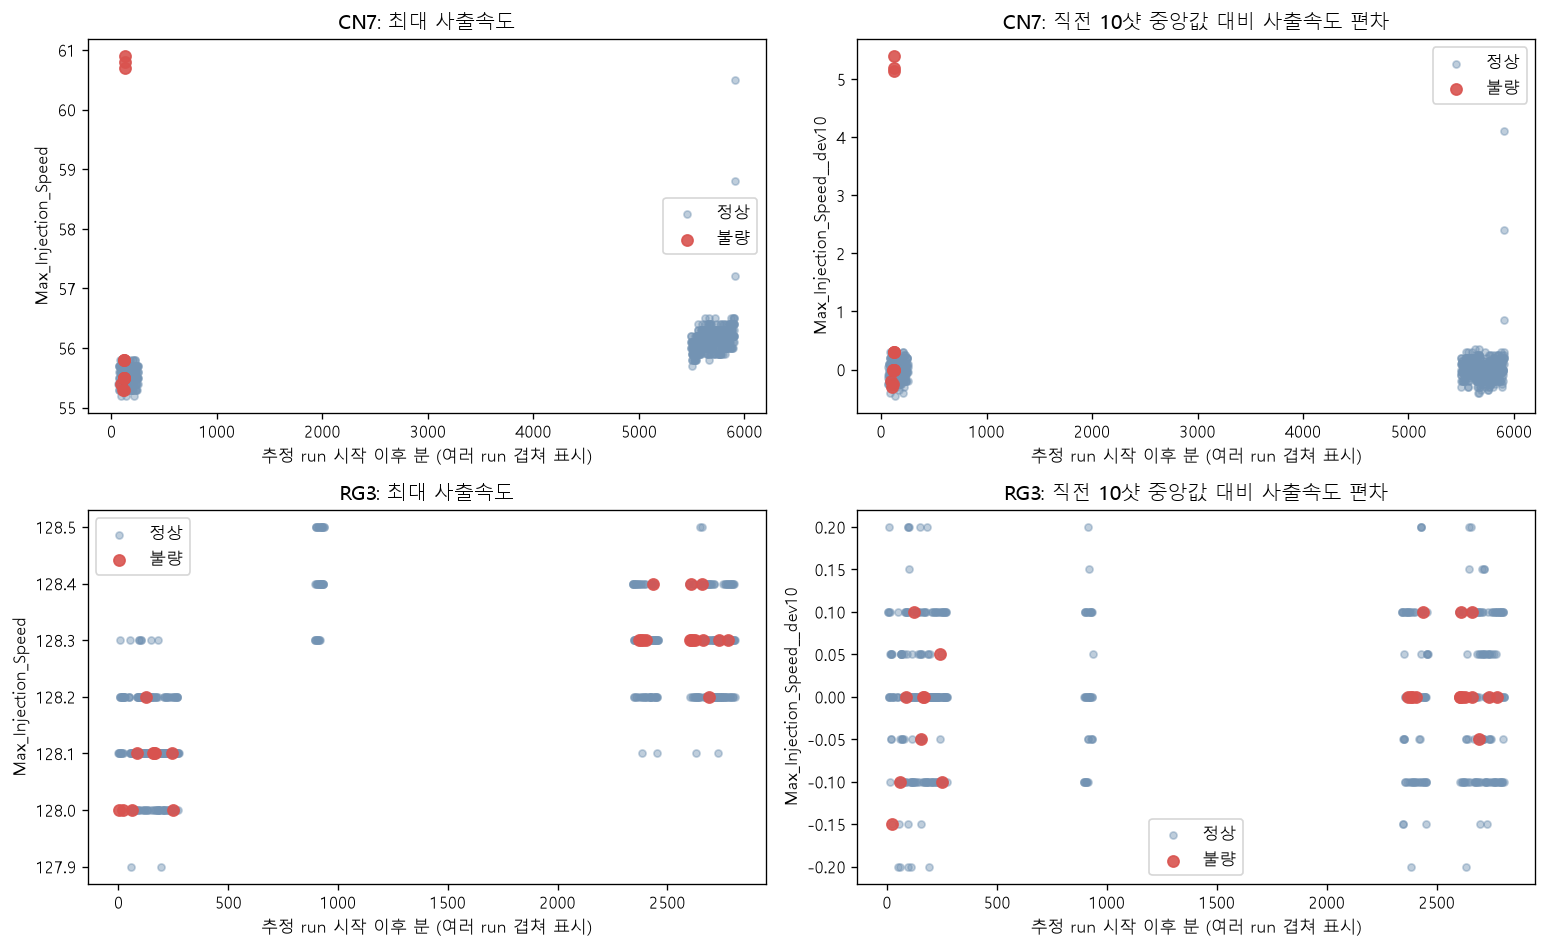

Saved reproducible tables and figures under reports/.


start                 end  shots   bad  runs
product label_block                                                           
CN7     1           2020-10-16 04:57:47 2020-10-16 08:05:18    188  14.0     1
        2           2020-10-19 23:24:46 2020-10-20 06:20:14    418   0.0     1
RG3     3           2020-10-21 00:16:26 2020-10-21 00:57:37     41   0.0     1
        4           2020-10-22 00:24:05 2020-10-22 02:20:26    103   5.0     1
        5           2020-10-22 04:40:26 2020-10-22 08:09:24    197  10.0     1
        6           2020-10-23 01:01:28 2020-10-23 02:36:11     74   4.0     1
        7           2020-10-23 04:41:48 2020-10-23 07:46:03    176   6.0     1

,feature,all_normal_mean,same_block_normal_mean,bad_mean,global_difference,same_block_difference,all_auc_high,same_block_auc_high
0,Mold_Temperature_3,23.330743,25.019540,25.071429,1.740685,0.051889,0.897804,0.652299
1,Mold_Temperature_4,24.850000,27.609771,27.657143,2.807143,0.047373,0.894788,0.642036
2,Plasticizing_Position,68.590710,68.841837,68.843569,0.252859,0.001731,0.868726,0.553366
3,Max_Back_Pressure,37.938176,37.164943,37.178571,-0.759605,0.013628,0.169040,0.571839
4,Max_Injection_Speed,55.975507,55.539080,56.664286,0.688779,1.125205,0.327522,0.592775
5,mold_delta,1.519257,2.590230,2.585715,1.066458,-0.004516,0.854790,0.505952


Barrel_Temperature_5  \
run_id              PassOrFail                         
20201020_092218_RG3 0.0                   265.000000   
                    1.0                   265.100006   
20201023_010128_RG3 0.0                   264.899994   
                    1.0                   265.000000   
20201023_031215_RG3 0.0                   265.000000   
                    1.0                   265.250000   

                                Barrel_Temperature_5__past10_std  
run_id              PassOrFail                                    
20201020_092218_RG3 0.0                                 0.290689  
                    1.0                                 0.365144  
20201023_010128_RG3 0.0                                 0.292115  
                    1.0                                 0.245173  
20201023_031215_RG3 0.0                                 0.304756  
                    1.0                                 0.346361

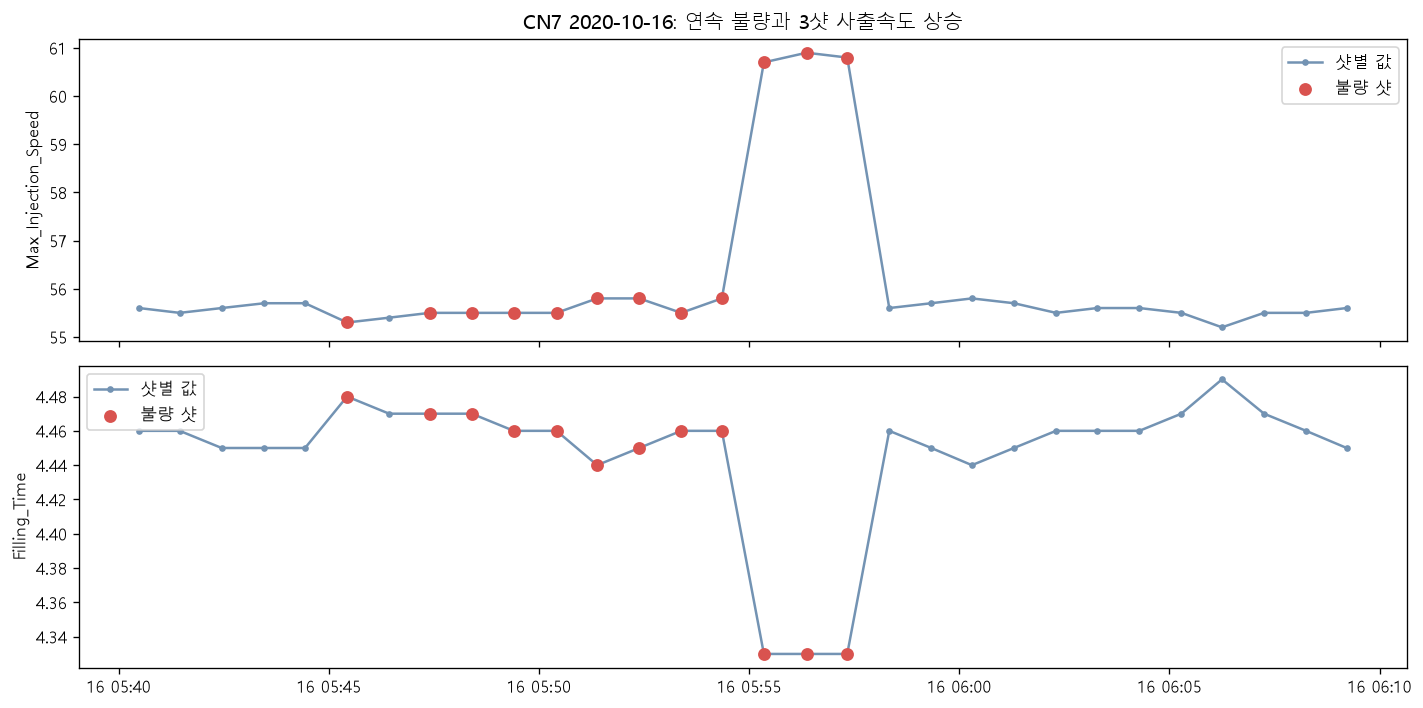

Verified: 2,393 rows -> 1,197 shots; 42 defective rows -> 39 defective shots; past-only rolling features.


In [7]:
same_value_rows = []
for p,g in contest.groupby('product'):
    for f in ['Max_Injection_Speed','Max_Injection_Pressure','Mold_Temperature_3','Mold_Temperature_4','Plasticizing_Position']:
        grouped = g.assign(value=g[f].round(2)).groupby('value')
        for val, vg in grouped:
            if vg.PassOrFail.nunique()>1:
                same_value_rows.append({'product':p,'feature':f,'value_rounded_2':val,
                                        'normal_shots':int(vg.PassOrFail.eq(0).sum()),
                                        'bad_shots':int(vg.PassOrFail.eq(1).sum()),
                                        'runs':vg.run_id.nunique()})
same_values = pd.DataFrame(same_value_rows)
same_values.to_csv(TABLES/'run_same_values_both_labels.csv',index=False)
quality_rows = []
for p,g in contest.groupby('product'):
    quality_rows.append({'product':p,'shots':len(g),
                         'avg_rpm_gt_max_fraction':float((g.Average_Screw_RPM>g.Max_Screw_RPM).mean()),
                         'avg_back_pressure_gt_max_fraction':float((g.Average_Back_Pressure>g.Max_Back_Pressure).mean()),
                         'cushion_median':g.Cushion_Position.median(),
                         'clamp_open_median':g.Clamp_Open_Position.median(),
                         'cushion_minus_clamp_open_median':(g.Cushion_Position-g.Clamp_Open_Position).median()})
sensor_quality = pd.DataFrame(quality_rows)
sensor_quality.to_csv(TABLES/'run_sensor_semantics_checks.csv',index=False)
display(same_values.head(15))
display(sensor_quality)
# CN7 early defect episode: exact shot pattern and previous values.
cn = contest.loc[contest['product'].eq('CN7') & contest.PassOrFail.eq(1)]
display(cn[['TimeStamp','run_id','observed_shot_seq','Reason','Max_Injection_Speed',
            'Max_Injection_Speed__delta1','Filling_Time','Filling_Time__dev10',
            'Mold_Temperature_3','mold_delta']])
# Defect type counts refer to shots; mixed gas+short-shot shots may contribute to both types.
reason_rows = []
for reason in ['가스','미성형']:
    for p,g in contest.groupby('product'):
        b = g.loc[g.Reason.str.contains(reason,regex=False)]
        n = g.loc[g.PassOrFail.eq(0)]
        for f in ['Max_Injection_Speed','Filling_Time','Mold_Temperature_3','mold_delta',
                  'Max_Injection_Speed__delta1','Mold_Temperature_3__dev10']:
            reason_rows.append({'reason':reason,'product':p,'feature':f,'bad_shots':len(b),
                                'bad_median':b[f].median(),'normal_median':n[f].median()})
pd.DataFrame(reason_rows).to_csv(TABLES/'run_reason_feature_medians.csv',index=False,encoding='utf-8-sig')
# Compact plots of raw speed versus past-only deviation for each labeled run.
fig,axes=plt.subplots(2,2,figsize=(13,8))
for row,p in enumerate(['CN7','RG3']):
    g=contest.loc[contest['product'].eq(p)]
    for col,f in enumerate(['Max_Injection_Speed','Max_Injection_Speed__dev10']):
        ax=axes[row,col]
        for label,color,name in [(0,'#7393b3','정상'),(1,'#d9534f','불량')]:
            gg=g.loc[g.PassOrFail.eq(label)]
            ax.scatter(gg.run_elapsed_min,gg[f],s=18 if label==0 else 45,c=color,alpha=.45 if label==0 else .9,label=name)
        ax.set_title(f'{p}: '+('최대 사출속도' if col==0 else '직전 10샷 중앙값 대비 사출속도 편차'))
        ax.set_xlabel('추정 run 시작 이후 분 (여러 run 겹쳐 표시)')
        ax.set_ylabel(f); ax.legend()
fig.tight_layout()
fig.savefig(FIGURES/'run_speed_and_past_deviation.png',bbox_inches='tight')
plt.show()
print('Saved reproducible tables and figures under reports/.')

# 라벨 관측 구간은 생산 run과 다르다. 라벨 공백으로 관측 구간을 따로 표시한다.
contest=contest.sort_values(['product','TimeStamp']).reset_index(drop=True).copy()
label_gap=contest.groupby('product')['TimeStamp'].diff().dt.total_seconds()
contest['label_block']=(contest['product'].ne(contest['product'].shift())|label_gap.gt(1800)|label_gap.isna()).cumsum()
blocks=contest.groupby(['product','label_block']).agg(start=('TimeStamp','min'),end=('TimeStamp','max'),shots=('PassOrFail','size'),bad=('PassOrFail','sum'),runs=('run_id','nunique'))
blocks.to_csv(TABLES/'run_label_observation_blocks.csv',encoding='utf-8-sig')
display(blocks)
cn7=contest.loc[contest['product'].eq('CN7')]
early=cn7.loc[cn7.TimeStamp.dt.date.eq(pd.Timestamp('2020-10-16').date())]
rows=[]
for f in ['Mold_Temperature_3','Mold_Temperature_4','Plasticizing_Position','Max_Back_Pressure','Max_Injection_Speed','mold_delta']:
    a=cn7.loc[cn7.PassOrFail.eq(0),f].mean()
    n=early.loc[early.PassOrFail.eq(0),f].mean()
    b=early.loc[early.PassOrFail.eq(1),f].mean()
    rows.append({'feature':f,'all_normal_mean':a,'same_block_normal_mean':n,'bad_mean':b,
                 'global_difference':b-a,'same_block_difference':b-n,
                 'all_auc_high':auc_rank(cn7.PassOrFail.to_numpy(int),cn7[f].to_numpy(float)),
                 'same_block_auc_high':auc_rank(early.PassOrFail.to_numpy(int),early[f].to_numpy(float))})
context=pd.DataFrame(rows)
context.to_csv(TABLES/'run_cn7_context_comparison.csv',index=False)
display(context)
rg=contest.loc[contest['product'].eq('RG3')]
v=rg.groupby(['run_id','PassOrFail'])[['Barrel_Temperature_5','Barrel_Temperature_5__past10_std']].median()
v.to_csv(TABLES/'run_rg3_barrel5_variability.csv')
display(v)
episode=early.loc[early.TimeStamp.between('2020-10-16 05:40','2020-10-16 06:10')]
episode[['TimeStamp','PassOrFail','Reason','Max_Injection_Speed','Filling_Time','Mold_Temperature_3','mold_delta']].to_csv(TABLES/'run_cn7_defect_episode.csv',index=False,encoding='utf-8-sig')
fig,axs=plt.subplots(2,1,figsize=(12,6),sharex=True)
for ax,f in zip(axs,['Max_Injection_Speed','Filling_Time']):
    ax.plot(episode.TimeStamp,episode[f],color='#7393b3',marker='.',label='샷별 값')
    b=episode.loc[episode.PassOrFail.eq(1)]
    ax.scatter(b.TimeStamp,b[f],color='#d9534f',s=45,label='불량 샷',zorder=3)
    ax.set_ylabel(f);ax.legend()
axs[0].set_title('CN7 2020-10-16: 연속 불량과 3샷 사출속도 상승')
fig.tight_layout()
fig.savefig(FIGURES/'run_cn7_episode.png',bbox_inches='tight')
plt.show()
assert len(contest)==1197 and contest.PassOrFail.sum()==39
assert run_summary.labeled_shots.sum()==1197 and run_summary.bad_shots.sum()==39
assert raw.loc[raw.in_competition,'PassOrFail'].sum()==42
probe=shots.loc[shots.run_id.eq('20201016_035120_CN7')].reset_index(drop=True)
expected=probe.Max_Injection_Speed.shift(1).rolling(10,min_periods=5).median()
np.testing.assert_allclose(probe.Max_Injection_Speed__past10_median,expected,equal_nan=True)
print('Verified: 2,393 rows -> 1,197 shots; 42 defective rows -> 39 defective shots; past-only rolling features.')
